# PCamCNN — results and report figures

Every figure here reads from a file on disk. Nothing in this notebook
recomputes a metric that already exists in `models/RESULTS.md`, in a
checkpoint, or in `artifacts/`. If a figure disagrees with the results
table, that is a bug, not a judgement call.

Run from the repo root with the `pcam` kernel selected.

| source | what it holds |
|---|---|
| `models/RESULTS.md` | one row per training run, with the command that produced it |
| `models/fp32_best.pt`, `models/qat_int8_best.pt` | checkpoints and their own metrics |
| `artifacts/weights/params.npz` | int8 weights, int32 biases, M0/shift |
| `artifacts/vectors/test_golden_scores.i32` | per-tile integer score from the golden model |
| `artifacts/vectors/test_tiles.bin.labels.u8` | ground truth for those tiles |

The golden scores are the reference the HLS kernel must reproduce exactly,
so plots built on them show the decision variable in the form the hardware
actually emits.

In [2]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix

REPO = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if os.path.basename(REPO) != "PCAMCNN":
    REPO = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
PHASE1 = os.path.join(REPO, "phase1_software")
ART = os.path.join(REPO, "artifacts")
MODELS = os.path.join(REPO, "models")
FIGS = os.path.join(REPO, "report", "figures")
os.makedirs(FIGS, exist_ok=True)
sys.path.insert(0, PHASE1)

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.size": 9, "axes.grid": True, "grid.alpha": 0.3,
})

def save(fig, name):
    """Write a figure to report/figures so the report never embeds a
    plot that exists only in notebook output."""
    p = os.path.join(FIGS, name)
    fig.savefig(p)
    print("wrote", p)

print("repo:", REPO)

repo: c:\GitRepos\PCAMCNN


## 1. Results table

Printed verbatim from `models/RESULTS.md`. This is the authoritative
record — every number quoted in the report comes from here.

In [3]:
with open(os.path.join(MODELS, "RESULTS.md"), encoding="utf-8") as f:
    print(f.read())

# Trained model results

One row per run. Never overwrite — append. A number that is not in this
table with the command that produced it does not go in the report.

| date | model | epochs | batch | lr | seed | val acc | val AUC | test acc | test AUC | wall | device | ckpt |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 2026-10-28 14:06 | PCamCNN FP32 | 30 | 256 | 0.001 | 0 | 0.8878 | 0.9604 | 0.8115 | 0.9134 | 42 min | NVIDIA GeForce RTX 5070 Ti Laptop GPU | `models\fp32_best.pt` |

<!-- command: python.exe phase1_software\train.py --epochs 30 --seed 0 --out models\fp32_best.pt -->
| 2026-10-28 18:31 | PCamCNN FP32 | 10 | 256 | 0.0001 | 0 | 0.8831 | 0.9556 | 0.8311 | 0.9354 | 14 min | NVIDIA GeForce RTX 5070 Ti Laptop GPU | `models/qat_int8_best.pt` |

<!-- command: python.exe phase1_software/qat.py --init models/fp32_best.pt --epochs 10 -->



## 2. Golden model score distribution

The integer score is `logit[1] - logit[0]` straight out of the FC layer,
with no scaling. This is the exact value the kernel will write to the HBM
result buffer, so the separation visible here is the separation the
hardware produces.

The decision threshold is 0 — a consequence of the output being an
unrequantized difference of two int32 accumulators, not a tuned
hyperparameter.

32,768 tiles, score range [-462,176, 507,197]
wrote c:\GitRepos\PCAMCNN\report\figures\golden_score_distribution.png


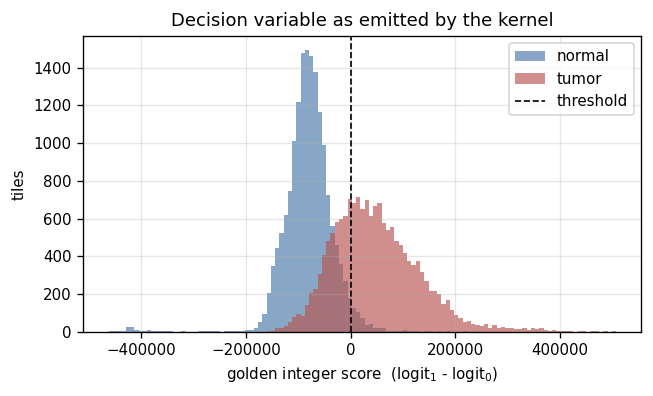

In [4]:
scores = np.fromfile(os.path.join(ART, "vectors", "test_golden_scores.i32"), dtype=np.int32)
labels = np.fromfile(os.path.join(ART, "vectors", "test_tiles.bin.labels.u8"), dtype=np.uint8)
labels = labels[:scores.size].astype(np.int64)
print(f"{scores.size:,} tiles, score range [{scores.min():,}, {scores.max():,}]")

fig, ax = plt.subplots(figsize=(6, 3.2))
bins = np.linspace(scores.min(), scores.max(), 120)
ax.hist(scores[labels == 0], bins=bins, alpha=0.65, label="normal", color="#4878a8")
ax.hist(scores[labels == 1], bins=bins, alpha=0.65, label="tumor", color="#b8544f")
ax.axvline(0, color="k", lw=1, ls="--", label="threshold")
ax.set_xlabel("golden integer score  (logit$_1$ - logit$_0$)")
ax.set_ylabel("tiles")
ax.set_title("Decision variable as emitted by the kernel")
ax.legend()
save(fig, "golden_score_distribution.png")

## 3. ROC — integer golden model

Computed directly from the integer scores. ROC is rank-based, so no
calibration or scaling is needed; the int32 values order the tiles
exactly as the hardware will.

golden: accuracy 0.8313   AUC 0.9354
wrote c:\GitRepos\PCAMCNN\report\figures\roc_golden.png


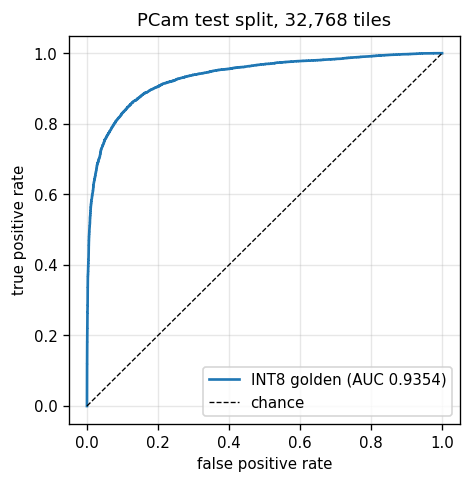

In [5]:
fpr, tpr, _ = roc_curve(labels, scores)
auc_golden = roc_auc_score(labels, scores)
pred = (scores > 0).astype(np.int64)
acc_golden = (pred == labels).mean()
print(f"golden: accuracy {acc_golden:.4f}   AUC {auc_golden:.4f}")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.plot(fpr, tpr, lw=1.6, label=f"INT8 golden (AUC {auc_golden:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="chance")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("PCam test split, 32,768 tiles")
ax.legend(loc="lower right")
save(fig, "roc_golden.png")

## 4. FP32 vs INT8

The only cell that runs a model. Scores are cached to
`models/test_scores.npz`; delete that file to force a recompute. Caching
matters because every figure downstream must come from the same scores as
the table above, not from a fresh run that might differ.

In [6]:
cache = os.path.join(MODELS, "test_scores.npz")

if os.path.exists(cache):
    z = np.load(cache)
    fp32_score, int8_score = z["fp32"], z["int8"]
    print("loaded cached scores")
else:
    import torch
    from data import PCamH5, to_float01
    from model import PCamCNN
    from qat import QuantPCamCNN

    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    ds = PCamH5(os.path.join(REPO, "data"), "test")

    def run(model):
        model = model.to(dev).eval()
        out = []
        with torch.no_grad():
            for i in range(0, len(ds), 512):
                xb = np.stack([ds[j][0].numpy() for j in range(i, min(i + 512, len(ds)))])
                lg = model(to_float01(torch.from_numpy(xb).to(dev)))
                out.append((lg[:, 1] - lg[:, 0]).float().cpu().numpy())
                print(f"  {min(i+512, len(ds))}/{len(ds)}", end="\r")
        return np.concatenate(out)

    m = PCamCNN(); m.load_state_dict(torch.load(os.path.join(MODELS, "fp32_best.pt"),
                                                map_location="cpu", weights_only=True)["model"])
    fp32_score = run(m)
    q = QuantPCamCNN(); q.load_state_dict(torch.load(os.path.join(MODELS, "qat_int8_best.pt"),
                                                     map_location="cpu", weights_only=True)["model"])
    int8_score = run(q)
    np.savez(cache, fp32=fp32_score, int8=int8_score)
    print("\ncached to", cache)

for name, s in [("FP32", fp32_score), ("INT8 brevitas", int8_score),
                ("INT8 golden", scores.astype(np.float64))]:
    print(f"{name:<14} acc {((s > 0).astype(np.int64) == labels).mean():.4f}   "
          f"AUC {roc_auc_score(labels, s):.4f}")

c:\GitRepos\PCAMCNN\pcam_env\lib\site-packages\torch\_tensor.py:1679: UserWarning: Named tensors and all their associated APIs are an experimental feature and subject to change. Please do not use them for anything important until they are released as stable. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\c10/core/TensorImpl.h:1976.)
  return super().rename(names)


  32768/32768
cached to c:\GitRepos\PCAMCNN\models\test_scores.npz
FP32           acc 0.8114   AUC 0.9135
INT8 brevitas  acc 0.8308   AUC 0.9355
INT8 golden    acc 0.8313   AUC 0.9354


wrote c:\GitRepos\PCAMCNN\report\figures\roc_fp32_vs_int8.png


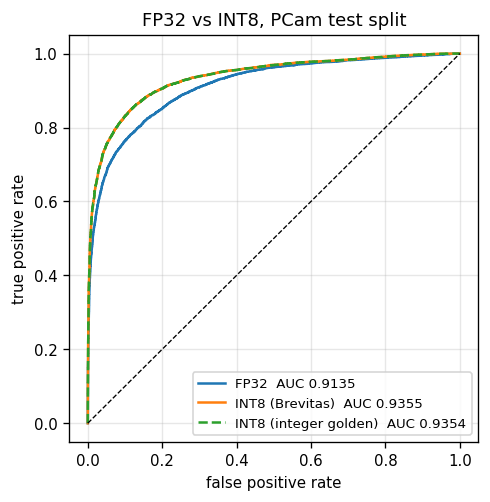

In [7]:
fig, ax = plt.subplots(figsize=(4.4, 4.4))
for name, s, style in [("FP32", fp32_score, "-"),
                       ("INT8 (Brevitas)", int8_score, "-"),
                       ("INT8 (integer golden)", scores.astype(np.float64), "--")]:
    f_, t_, _ = roc_curve(labels, s)
    ax.plot(f_, t_, style, lw=1.5, label=f"{name}  AUC {roc_auc_score(labels, s):.4f}")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("FP32 vs INT8, PCam test split")
ax.legend(loc="lower right", fontsize=8)
save(fig, "roc_fp32_vs_int8.png")

The golden and Brevitas curves should be visually indistinguishable.
They are not bit-identical — Brevitas simulates quantization in float and
carries rounding the integer model does not — but any visible gap would
mean the exported scales are wrong.

## 5. Confusion matrix

At threshold 0, on the golden integer scores.

wrote c:\GitRepos\PCAMCNN\report\figures\confusion_matrix.png
sensitivity 0.6943   specificity 0.9682
Sensitivity is the clinically relevant one: a missed tumor tile costs more than a false alarm a pathologist discards.


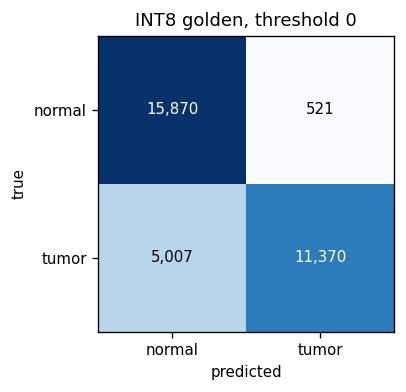

In [8]:
cm = confusion_matrix(labels, pred)
fig, ax = plt.subplots(figsize=(3.4, 3.2))
im = ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["normal", "tumor"])
ax.set_yticks([0, 1], ["normal", "tumor"])
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("INT8 golden, threshold 0")
ax.grid(False)
save(fig, "confusion_matrix.png")

tn, fp, fn, tp = cm.ravel()
print(f"sensitivity {tp/(tp+fn):.4f}   specificity {tn/(tn+fp):.4f}")
print("Sensitivity is the clinically relevant one: a missed tumor tile "
      "costs more than a false alarm a pathologist discards.")

## 6. Weight distributions per layer

From `artifacts/weights/params.npz` — the actual int8 values the kernel
will hold on-chip. Layers whose weights cluster near zero are wasting
quantization levels; layers pressed against ±127 are clipping. Neither
should be visible here.

wrote c:\GitRepos\PCAMCNN\report\figures\weight_distributions.png
total int8 weights: 134,320 B (131.2 KB) — resident on-chip


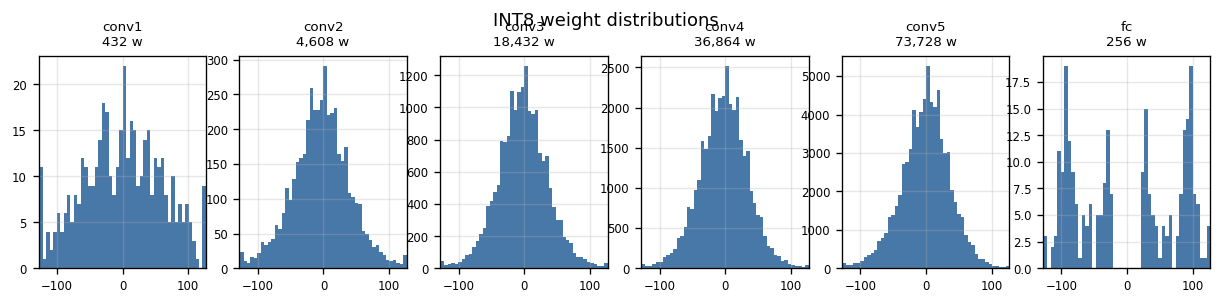

In [9]:
P = np.load(os.path.join(ART, "weights", "params.npz"))
convs = [k[:-2] for k in P.files if k.endswith("_w")]
fig, axes = plt.subplots(1, len(convs), figsize=(2.1 * len(convs), 2.3), sharey=False)
for ax, name in zip(np.atleast_1d(axes), convs):
    w = P[f"{name}_w"].ravel()
    ax.hist(w, bins=48, color="#4878a8")
    ax.set_title(f"{name}\n{w.size:,} w", fontsize=8)
    ax.set_xlim(-128, 127)
    ax.tick_params(labelsize=7)
fig.suptitle("INT8 weight distributions", y=1.04)
save(fig, "weight_distributions.png")

total = sum(P[f"{n}_w"].nbytes for n in convs)
print(f"total int8 weights: {total:,} B ({total/1024:.1f} KB) — resident on-chip")

## 7. Requantization multipliers

`M0` and `shift` per layer. These encode `M = s_in * s_w / s_out` as
`M0 * 2^-shift`. The shift values determine the intermediate width the
HLS kernel needs: with `shift` near 40 and accumulators near 2^25, the
product needs roughly 56 bits, so the kernel requires an `ap_int<64>`
intermediate rather than int32.

In [10]:
print(f"{'layer':<8} {'shift min':>10} {'shift max':>10} {'M0 min':>14} {'M0 max':>14}")
print("-" * 60)
worst = 0
for name in [k[:-6] for k in P.files if k.endswith("_shift")]:
    sh, m0 = P[f"{name}_shift"], P[f"{name}_m0"]
    print(f"{name:<8} {sh.min():>10} {sh.max():>10} {m0.min():>14,} {m0.max():>14,}")
    worst = max(worst, int(sh.max()))
print(f"\nmax shift = {worst}")
print(f"acc(~2^25) * M0(~2^31) needs ~{25 + 31} bits -> ap_int<64> intermediate in HLS")

layer     shift min  shift max         M0 min         M0 max
------------------------------------------------------------
conv1            39         41  1,077,779,270  2,095,944,001
conv2            38         40  1,074,840,642  2,123,669,022
conv3            39         40  1,077,231,793  2,142,113,419
conv4            40         41  1,098,006,537  2,146,274,874
conv5            40         41  1,074,863,446  2,138,266,890
gap              35         35  1,409,242,352  1,409,242,352

max shift = 41
acc(~2^25) * M0(~2^31) needs ~56 bits -> ap_int<64> intermediate in HLS


## 8. Per-layer activation ranges

Runs the golden model on a handful of tiles with `dump=` enabled and
reports the range each stage actually occupies. Two things to read here:

- **Accumulator headroom.** `*_acc` rows must stay inside int32. The
  theoretical worst case is 576 terms x 32,385 = 18.6M; what matters is
  the observed value, since that is what the kernel will see.
- **Activation range use.** A stage whose post-requantization values
  never approach 255 is wasting dynamic range, which shows up as lost
  accuracy and is worth mentioning in the report.

In [11]:
import golden as G
from data import PCamH5

ds = PCamH5(os.path.join(REPO, "data"), "test")
tiles = np.stack([ds[i][0].numpy() for i in range(16)])

agg = {}
for t in tiles:
    d = {}
    G.forward_tile(t, {k: P[k] for k in P.files}, dump=d)
    for k, v in d.items():
        lo, hi = int(v.min()), int(v.max())
        if k in agg:
            agg[k] = (min(agg[k][0], lo), max(agg[k][1], hi))
        else:
            agg[k] = (lo, hi)

print(f"{'stage':<14} {'min':>12} {'max':>12}   {'note':<28}")
print("-" * 70)
INT32 = 2**31 - 1
for k, (lo, hi) in agg.items():
    note = ""
    if k.endswith("_acc"):
        note = f"{100*max(abs(lo), hi)/INT32:.3f}% of int32"
    elif not k.startswith("fc"):
        note = f"{100*hi/255:.0f}% of uint8 range used"
    print(f"{k:<14} {lo:>12,} {hi:>12,}   {note:<28}")

stage                   min          max   note                        
----------------------------------------------------------------------
conv1_acc          -141,156      147,378   0.007% of int32             
conv1                     0          255   100% of uint8 range used    
conv1_pool                0          255   100% of uint8 range used    
conv2_acc          -132,874      106,479   0.006% of int32             
conv2                     0          255   100% of uint8 range used    
conv2_pool                0          255   100% of uint8 range used    
conv3_acc          -385,262      174,611   0.018% of int32             
conv3                     0          255   100% of uint8 range used    
conv3_pool                0          255   100% of uint8 range used    
conv4_acc          -408,001      243,318   0.019% of int32             
conv4                     0          255   100% of uint8 range used    
conv4_pool                0          255   100% of uint8 range us

wrote c:\GitRepos\PCAMCNN\report\figures\accumulator_headroom.png


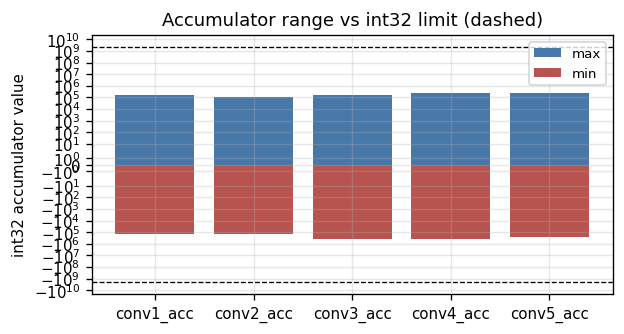

In [12]:
accs = {k: v for k, v in agg.items() if k.endswith("_acc")}
fig, ax = plt.subplots(figsize=(5.6, 2.8))
names = list(accs)
lows = [accs[k][0] for k in names]
highs = [accs[k][1] for k in names]
ax.bar(names, highs, color="#4878a8", label="max")
ax.bar(names, lows, color="#b8544f", label="min")
ax.axhline(INT32, color="k", ls="--", lw=0.8)
ax.axhline(-INT32, color="k", ls="--", lw=0.8)
ax.set_yscale("symlog")
ax.set_ylabel("int32 accumulator value")
ax.set_title("Accumulator range vs int32 limit (dashed)")
ax.legend(fontsize=8)
save(fig, "accumulator_headroom.png")

## 9. Part 2 and 3 placeholders

Fill these once the kernel exists. Keeping the structure here means the
report's figure list is fixed now and only the data arrives later.

- **Bit-exactness** — count of tiles where the HLS kernel's int32 score
  differs from `test_golden_scores.i32`. The target is zero, and anything
  else is a table of which layer diverged first.
- **DSE** — from `phase2_hls/reports/DSE_LOG.md`: II, latency, LUT, FF,
  BRAM, URAM, DSP per pragma variant.
- **Throughput** — tiles/s for one, two and four U280s, with scaling
  efficiency against the 1.7x two-card target.
- **Baselines** — GPU and CPU inference throughput from
  `bench_baseline.py`, measured on this same test split.